# Physics Baseline

In [1]:
import os
import glob
import numpy as np
np.random.seed(1234567)
import pandas as pd

import matplotlib.pyplot as plt
import matplotlib.image as mpimg

import re
import warnings
warnings.filterwarnings('ignore')

In [2]:
# Automatically detect if running on Kaggle or Locally
IS_KAGGLE = os.path.exists('/kaggle/input')
BASE_DIR = '/kaggle/input/competitions/rogii-wellbore-geology-prediction' if IS_KAGGLE else '../data'

print(f"Running on {'Kaggle' if IS_KAGGLE else 'Local Environment'}")
print(f"Data Directory: {BASE_DIR}")

Running on Local Environment
Data Directory: ../data


In [3]:
train_data = os.path.join(BASE_DIR, "train")
file_paths = sorted(os.listdir(train_data))
file_paths[:10]

['000d7d20.png',
 '000d7d20__horizontal_well.csv',
 '000d7d20__typewell.csv',
 '00bbac68.png',
 '00bbac68__horizontal_well.csv',
 '00bbac68__typewell.csv',
 '00e12e8b.png',
 '00e12e8b__horizontal_well.csv',
 '00e12e8b__typewell.csv',
 '015fe0d2.png']

In [4]:
# Regex pattern: 
pattern = re.compile(r'([^/\\]+)__horizontal_well\.csv')

well_names = []
for path in file_paths:
    match = pattern.search(path)
    if match:
        well_names.append(match.group(1))

print("Extracted Well Names:")
print(len(well_names), "Well Names")

Extracted Well Names:
773 Well Names


In [350]:
well = np.random.choice(well_names)

hw = pd.read_csv(train_data + f"/{well}__horizontal_well.csv")
tw = pd.read_csv(train_data + f"/{well}__typewell.csv")
pic = train_data + f"/{well}.png"

# Good Scoring:
'729f4217'
'ff0aea78'
# Bad Scoring:
'493b5b31'
'8f201368: Multiple Breaks without Peaks in the beginning'
'c99f9fae: Bad Ending' 
'2e63d9de: Unable to capture the rising TVT, one crest behind'
'511e1db0: One crest fails to match, rest gets matched'

well, hw.shape, tw.shape

(np.str_('dafc88c3'), (7187, 13), (1330, 3))

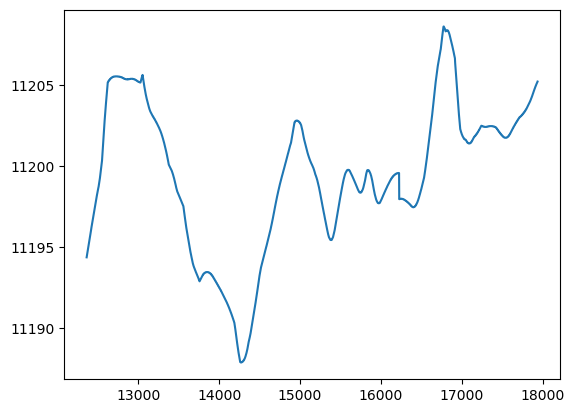

In [351]:
evalz = hw[hw['TVT_input'].isna()]
plt.plot(evalz['MD'], evalz['TVT']) # 

In [352]:
from scipy.signal import butter, filtfilt
def remove_rotation_noise(gr_series, cutoff=0.1):
    """
    Low pass filter.
    """
    # 1. Handle NaNs safely
    gr_filled = gr_series.interpolate(method='linear').bfill().ffill()
    
    # 2. Design the Butterworth Filter
    # Nyquist frequency is 0.5 (half of our 1-foot sample rate)
    nyquist = 0.5 
    normal_cutoff = cutoff / nyquist
    
    # Order 4 is strong enough to kill the noise without distorting the geology
    b, a = butter(1, normal_cutoff, btype='low', analog=False)
    
    # 3. Apply Zero-Phase Filtering
    gr_clean = filtfilt(b, a, gr_filled)
    
    # Put the NaNs back exactly where they were originally (if you need them)
    # gr_clean[gr_series.isna()] = np.nan 
    
    return gr_clean
    

In [353]:
from scipy.signal import find_peaks as p

def find_peaks(x_, y_, prominence=30.0, distance=70):

    # x = x_.copy().reset_index(drop=True)
    # y = y_.copy().reset_index(drop=True)
    
    # 2. Find the Prominent Peaks
    # The 'prominence' value requires tuning based on your specific data's scale.
    # 'distance' ensures you don't get two peaks right next to each other.
    peaks, properties = p(y, prominence=prominence, distance=distance)
    
    # 3. Calculate the boundaries (midpoints between major peaks)
    # We add the very beginning (0) and very end (length of array) to the boundaries
    midpoints = (peaks[:-1] + peaks[1:]) // 2
    boundaries = [0] + midpoints.tolist() + [len(y)]

    return peaks, properties, midpoints, boundaries
    

(50, 5572)

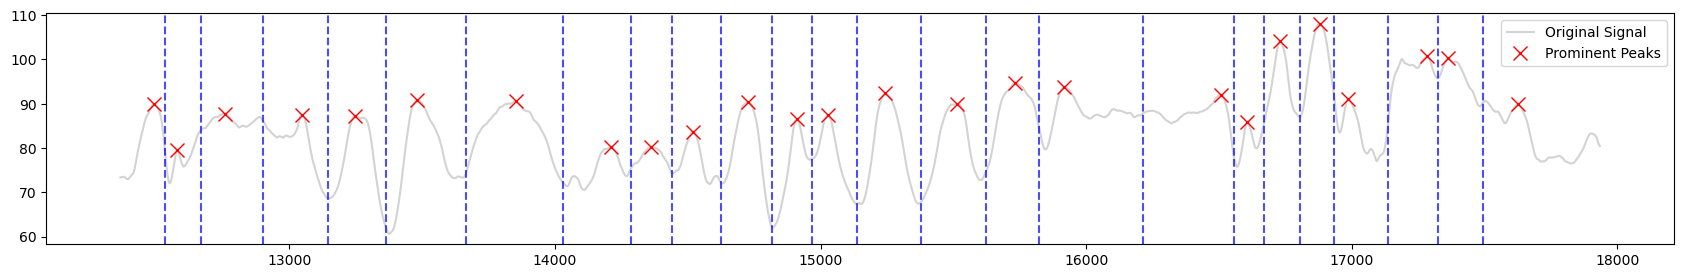

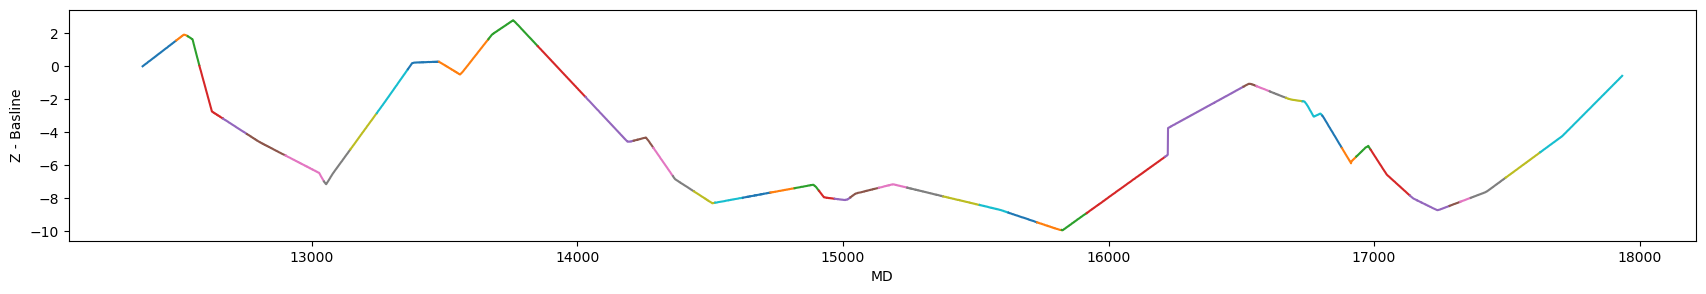

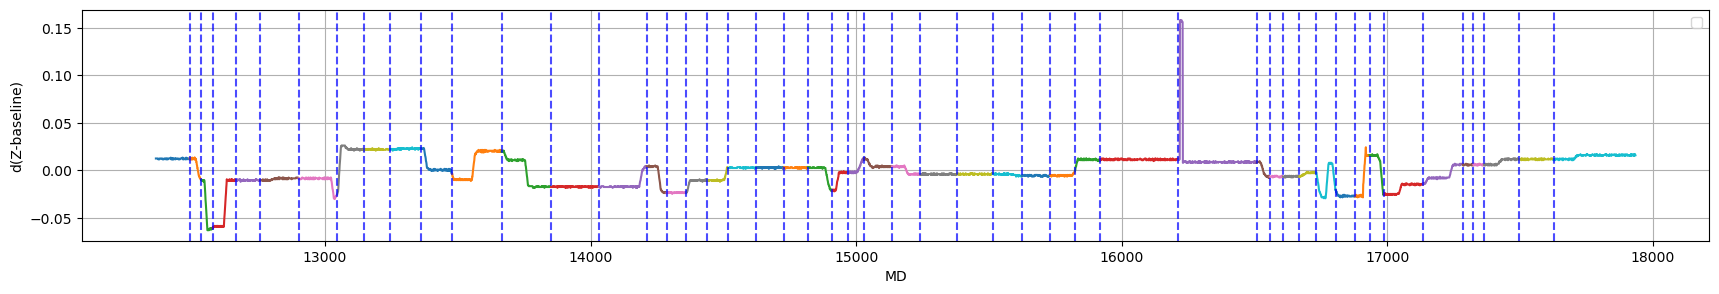

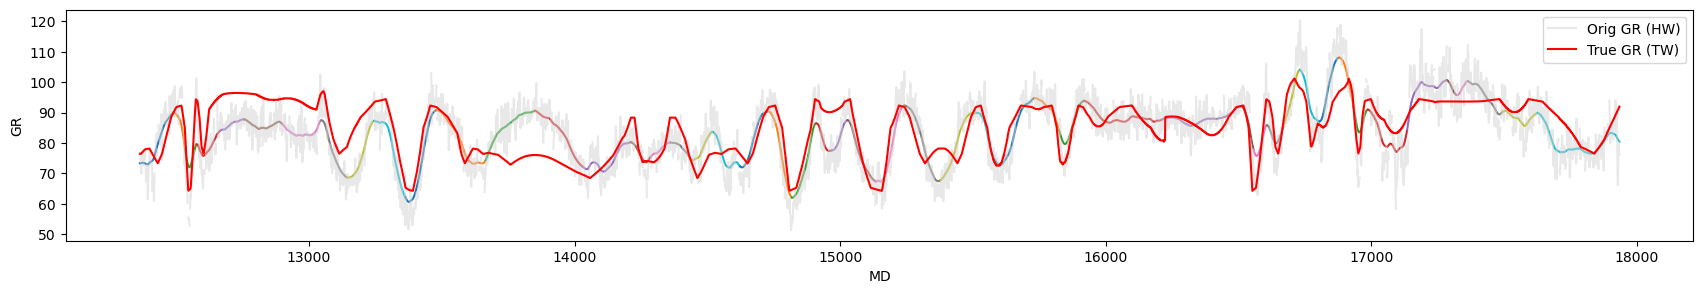

<Figure size 2100x300 with 0 Axes>

In [354]:
# Only to predict
mask = hw['TVT_input'].isna()
evalz = hw[mask].copy()

# Normalizing stuff
slope, intercept = np.polyfit(evalz['MD'], evalz['Z'], deg=1)
pred = evalz['Z'] - evalz['MD'] * slope - intercept
pred_norm = pred - pred.iloc[0] 
tvt_norm = -evalz['TVT'] + evalz['TVT'].iloc[0]
evalz['norm_TVT'] = tvt_norm
evalz['norm_Z'] = pred_norm
evalz['Z-bl'] = evalz['norm_TVT'] - evalz['norm_Z']
# evalz['GR'] = remove_rotation_noise(evalz['GR'], cutoff=0.007)
evalz['GR'] = remove_rotation_noise(evalz['GR'], cutoff=0.009)
fill = lambda df: df.interpolate(method='linear', limit_direction='both')
d = lambda df: fill(df).diff().rolling(11, center=True, min_periods=1).mean()
evalz['dZ-bl'] = d(evalz['Z-bl'])

# Making Chunks Containing major peaks in GR
plt.figure(figsize = (21, 3))
x = evalz['MD'].copy().reset_index(drop=True)
y = evalz['GR'].copy().reset_index(drop=True)
peaks, properties, midpoints, boundaries = find_peaks(x, y, prominence=3.0, distance=70)
# peaks, properties, midpoints, boundaries = find_peaks(x, y, prominence=0.7, distance=5)
plt.plot(x, y, color='lightgrey', label='Original Signal')
plt.plot(x[peaks], y[peaks], "x", color='red', markersize=10, label='Prominent Peaks')
plt.legend()
for i in range(len(boundaries) - 1):
    start_idx = boundaries[i]
    end_idx = boundaries[i+1]
    x_chopped = x[start_idx:end_idx]
    y_chopped = y[start_idx:end_idx]
    if i > 0:
        plt.axvline(x=x[start_idx], color='blue', linestyle='--', alpha=0.7)
boundaries += (peaks.tolist())
boundaries.sort()

chunks = [evalz.iloc[boundaries[i]:boundaries[i+1]] for i in range(len(boundaries)-1)]

# Z-TVT
plt.figure(figsize=(21, 3))
for chunk in chunks:
    plt.plot(chunk['MD'], chunk['Z-bl'])    
plt.xlabel("MD")
plt.ylabel("Z - Basline")

# d(Z - baseline)
plt.figure(figsize = (21, 3))
for chunk in chunks:
    plt.plot(chunk['MD'], chunk['dZ-bl'])
plt.xlabel("MD")
plt.ylabel("d(Z-baseline)")
plt.grid(True)
plt.legend()
for i in range(len(boundaries) - 1):
    start_idx = boundaries[i]
    end_idx = boundaries[i+1]
    if i > 0:
        plt.axvline(x=x[start_idx], color='blue', linestyle='--', alpha=0.7)

# GR vs GR
plt.figure(figsize=(21, 3))
for chunk in chunks:
    plt.plot(chunk['MD'], chunk['GR'])
# gr = np.interp(hw[mask]['TVT'], tw['TVT'], remove_rotation_noise(tw['GR'], cutoff=0.05)) 
gr = np.interp(hw[mask]['TVT'], tw['TVT'], tw['GR']) 
plt.plot(evalz['MD'], hw[mask]['GR'], color='lightgray', label="Orig GR (HW)", alpha=0.5)
plt.plot(evalz['MD'], gr, color='red', label="True GR (TW)")
plt.xlabel("MD")
plt.ylabel("GR")
plt.legend()

plt.figure(figsize=(21, 3))
# plt.plot(evalz['MD'], evalz['norm_Z'])
# m, c = np.polyfit(evalz['MD'], evalz['Y'], deg=1)
# plt.plot(evalz['MD'], evalz['Y'] - m * evalz['MD'] - c)
# plt.plot(evalz[

len(chunks), len(evalz)

In [355]:
np.arctan(slope)

np.float64(-0.01738643637006927)

## Hypothesis:
* Star steer calculates $TVT - TVT_0 = |Z| - |Z_0| - (m * MD + c)$ for every chunk
    * Absolute Space &rarr; Stratigraphic Space
    * Where $m and c$ are optimized to have the best $GR$ wave match using this chunk and the other chunks
    * The $TVT_0$ for the other chunk is choosen to be the last predicted $TVT$ in the chunk

## Flow:
* Find how division in chunks could be replicated close to the geologist's division.
    * Making chunks on the basis of points of inflection/maximas/minimas/their midpoints.
* You have $TVT_{start}$ with $Z_{start}$ and $Z_{end}$ for a chunk.
* You want $TVT_{b/w}$
    * Such that the points with $start$ and $end$ form a straight line in TVT + Z vs MD.
    * Match GR
        * ME: Such that the interp from tw is maximized in correlation with GR in the chunk.
        * Geologist: Mathing bit by bit the GR of hw to tw's.
* Match GR vs np.interp(TVT) from Zi to Zi + 1, hence get TVTi + 1
* $ TVT = m * (Z - Z_i) + TVT_i $

* Using beam search

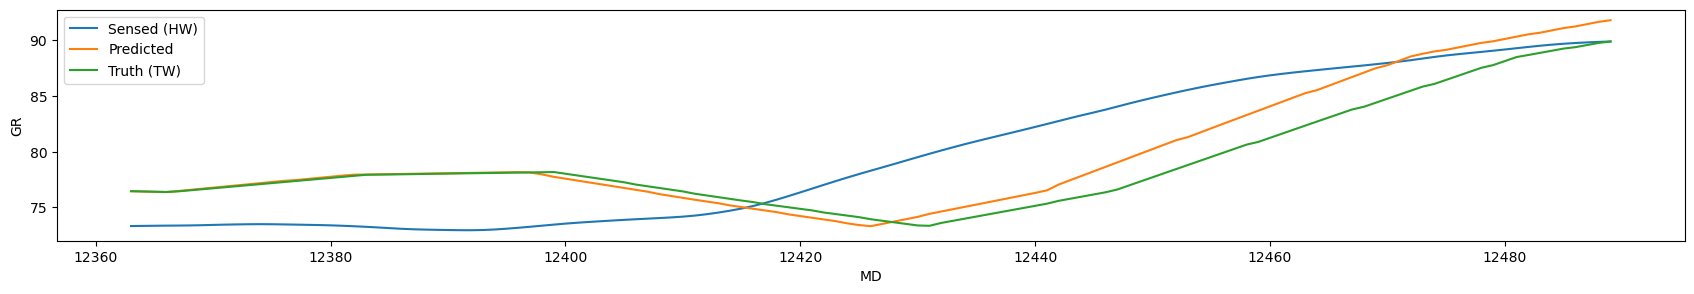

In [356]:
tvt_0 = chunks[0]['TVT'].iloc[0]
for chunk in chunks:
    plt.figure(figsize=(21, 3))
    md_0 = chunk['MD'].iloc[0]
    plt.plot(chunk['MD'], chunk['GR'], label='Sensed (HW)')

    ms = [0.05, 0.04, 0.03, 0.02, 0.01, 0, -0.01, -0.02, -0.03, -0.04, -0.05]
    m = -0.01 # Tunable
    tvt = m * (chunk['MD'] - md_0) - (chunk['norm_Z'] - chunk['norm_Z'].iloc[0]) + tvt_0
    tvt_0 = tvt.iloc[-1]
    gr = np.interp(tvt, tw['TVT'], tw['GR']) 
    plt.plot(chunk['MD'], gr, label="Predicted")
    
    gr = np.interp(chunk['TVT'], tw['TVT'], tw['GR']) 
    plt.plot(chunk['MD'], gr, label="Truth (TW)")
    
    plt.xlabel("MD")
    plt.ylabel("GR")
    plt.legend()
    break

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.signal import find_peaks
from scipy.optimize import minimize_scalar
from scipy.stats import pearsonr


# CORRECTED: Dynamically chunk evalz based on the calculated boundaries
chunks = [evalz.iloc[boundaries[i]:boundaries[i+1]] for i in range(len(boundaries)-1)]

# --- AUTOMATED CONTINUOUS M-SELECTION WITH BEAM SEARCH (HYBRID SHAPE/MSE) ---
ms = [0.05, 0.04, 0.03, 0.02, 0.01, 0, -0.01, -0.02, -0.03, -0.04, -0.05]
# initial_tvt_0 = chunks[0]['TVT'].iloc[0]
initial_tvt_0 = hw[~mask]['TVT'].iloc[-1]
beam_width = 30 

# Define the dynamic cost function for the optimizer
def shape_aware_cost(m_cand, chunk, md_0, current_tvt_0):
    tvt_cand = m_cand * (chunk['MD'] - md_0) - (chunk['norm_Z'] - chunk['norm_Z'].iloc[0]) + current_tvt_0
    gr_cand = np.interp(tvt_cand, tw['TVT'], tw['GR']) 
    
    # Filter valid data points
    valid = ~np.isnan(chunk['GR']) & ~np.isnan(gr_cand)
    if np.sum(valid) < 10:
        return 1e6 # Heavy penalty for invalid/empty overlaps

    gr_sensed = chunk['GR'][valid]
    gr_pred = gr_cand[valid]
    
    # Dynamic Routing: Check if chunk has a prominent peak using Standard Deviation
    # A standard deviation > 10 API usually indicates we are looking at a real geological feature
    if np.std(gr_sensed) > 10.0:
        # Prevent division by zero if the prediction is completely flat
        if np.std(gr_pred) < 1e-5:
            return 1e6 
            
        # Shape Matching: Maximize correlation coefficient (1.0 is perfect shape match)
        corr, _ = pearsonr(gr_sensed, gr_pred)
        
        # We return (1.0 - corr) because the optimizer wants to *minimize* the result
        return 1.0 - corr if not np.isnan(corr) else 1e6
    else:
        # Baseline Matching: Minimize MSE for flat/noisy shale sections
        return np.mean((gr_sensed - gr_pred)**2)

# Initialize beams. Each beam holds the state of a specific route through the chunks.
beams = [{
    "tvt_0": initial_tvt_0,
    "m_path": [],
    "total_error": 0.0,
    "tvt_cands": [],
    "gr_cands": [],
    "opt_types": []
}]

# Iterate through the chunks using Beam Search + Continuous Optimization
for i, chunk in enumerate(chunks):
    md_0 = chunk['MD'].iloc[0]
    new_beams = []
    
    # Determine the optimization type for logging
    valid_gr = chunk['GR'].dropna()
    is_shape = np.std(valid_gr) > 10.0 if len(valid_gr) > 0 else False
    opt_type = "Shape Correlation" if is_shape else "Baseline MSE"
    
    for beam in beams:
        # 1. Find the continuous local optimum for this specific beam's trajectory
        res = minimize_scalar(
            shape_aware_cost,
            # bounds=(-0.05, 0.05),
            bounds=(-0.5, 0.5),
            args=(chunk, md_0, beam["tvt_0"]),
            method='bounded'
        )
        best_m_cont = res.x
        
        # 2. Create branches: include the continuous optimum + the discrete grid look-ahead
        m_cands = list(set(ms + [best_m_cont]))
        
        for m_cand in m_cands:
            tvt_cand = m_cand * (chunk['MD'] - md_0) - (chunk['norm_Z'] - chunk['norm_Z'].iloc[0]) + beam["tvt_0"]
            gr_cand = np.interp(tvt_cand, tw['TVT'], tw['GR']) 
            
            # Evaluate the shape-aware cost for this branch
            chunk_error = shape_aware_cost(m_cand, chunk, md_0, beam["tvt_0"])
            
            new_beam = {
                "tvt_0": tvt_cand.iloc[-1],
                "m_path": beam["m_path"] + [m_cand],
                "total_error": beam["total_error"] + chunk_error,
                "tvt_cands": beam["tvt_cands"] + [tvt_cand],
                "gr_cands": beam["gr_cands"] + [gr_cand],
                "opt_types": beam["opt_types"] + [opt_type]
            }
            new_beams.append(new_beam)
            
    # Sort and prune beams
    new_beams.sort(key=lambda x: x["total_error"])
    beams = new_beams[:beam_width]

# Extract the overall best path
best_overall_path = beams[0]
best_m_sequence = best_overall_path["m_path"]
best_gr_sequence = best_overall_path["gr_cands"]
best_tvt_sequence = best_overall_path["tvt_cands"]
best_opt_sequence = best_overall_path["opt_types"]

# --- CALCULATE AND PRINT FINAL RMSE ---
final_tvt = pd.concat(best_tvt_sequence)
final_rmse = np.sqrt(np.nanmean((final_tvt - evalz['TVT'])**2))
print(f"Overall RMSE between Final Concatenated TVT and evalz['TVT']: {final_rmse:.6f}")

# --- PLOTTING THE OPTIMIZED CONTINUOUS RESULTS ---
for i, chunk in enumerate(chunks):
    plt.figure(figsize=(21, 3))
    
    best_m = best_m_sequence[i]
    best_pred_gr = best_gr_sequence[i]
    opt_type = best_opt_sequence[i]
    
    # Plotting the optimized results for this chunk
    plt.plot(chunk['MD'], chunk['GR'], label='Sensed (HW)')
    plt.plot(chunk['MD'], best_pred_gr, label=f"Predicted (m={best_m:.5f})")
    
    truth_gr = np.interp(chunk['TVT'], tw['TVT'], tw['GR']) 
    plt.plot(chunk['MD'], truth_gr, label="Truth (TW)", linestyle='--', alpha=0.7)
    
    plt.title(f"Chunk {i+1}: Optimized m = {best_m:.5f} (via {opt_type} + Beam Search)")
    plt.xlabel("MD")
    plt.ylabel("GR")
    plt.legend()

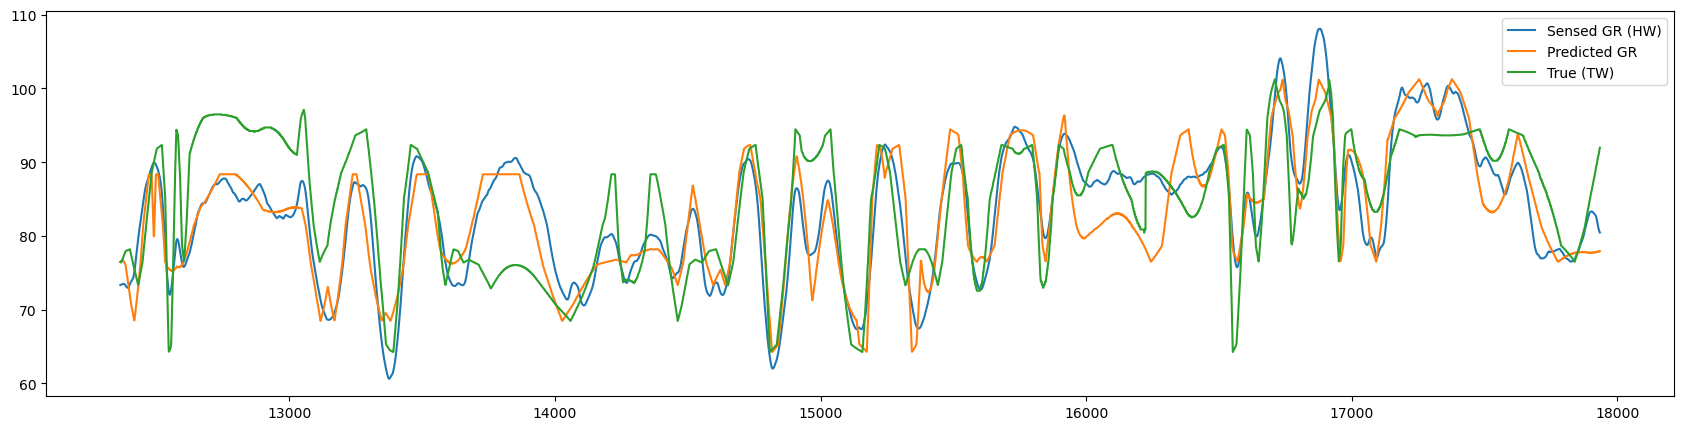

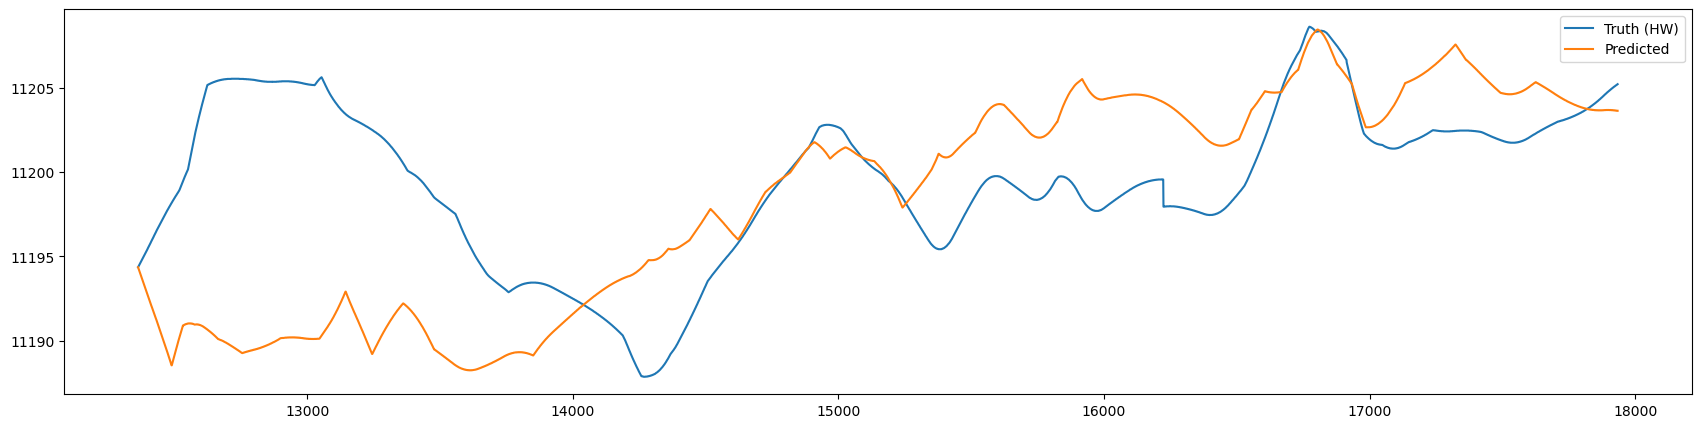

In [358]:
gr = np.concat(best_gr_sequence)
plt.figure(figsize=(21, 5))
plt.plot(evalz['MD'], evalz['GR'], label='Sensed GR (HW)')
plt.plot(evalz['MD'], gr, label='Predicted GR')
gr = np.interp(evalz['TVT'], tw['TVT'], tw['GR'])
plt.plot(evalz['MD'], gr, label='True (TW)')
plt.legend()
plt.figure(figsize=(21, 5))
plt.plot(evalz['MD'], evalz['TVT'], label='Truth (HW)')
plt.plot(evalz['MD'], final_tvt, label='Predicted')
plt.legend()
# plt.plot(evalz['MD'], -evalz['TVT'] + 2 * evalz['TVT'].iloc[0])

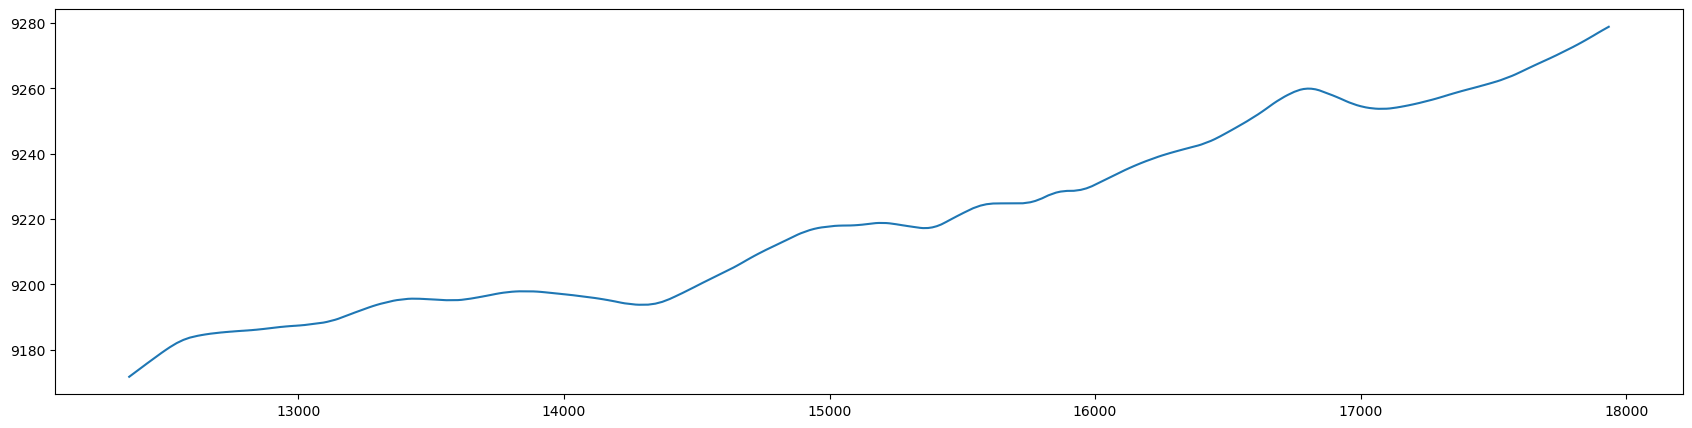

In [359]:
plt.figure(figsize=(21, 5))
# plt.plot(evalz['norm_TVT']-evalz['norm_Z'])
# print(evalz.columns)
plt.plot(evalz['MD'], -evalz['Z'])

In [360]:
np.sqrt(np.mean((np.abs(final_tvt - evalz['TVT']))**2))

np.float64(6.576446505383029)

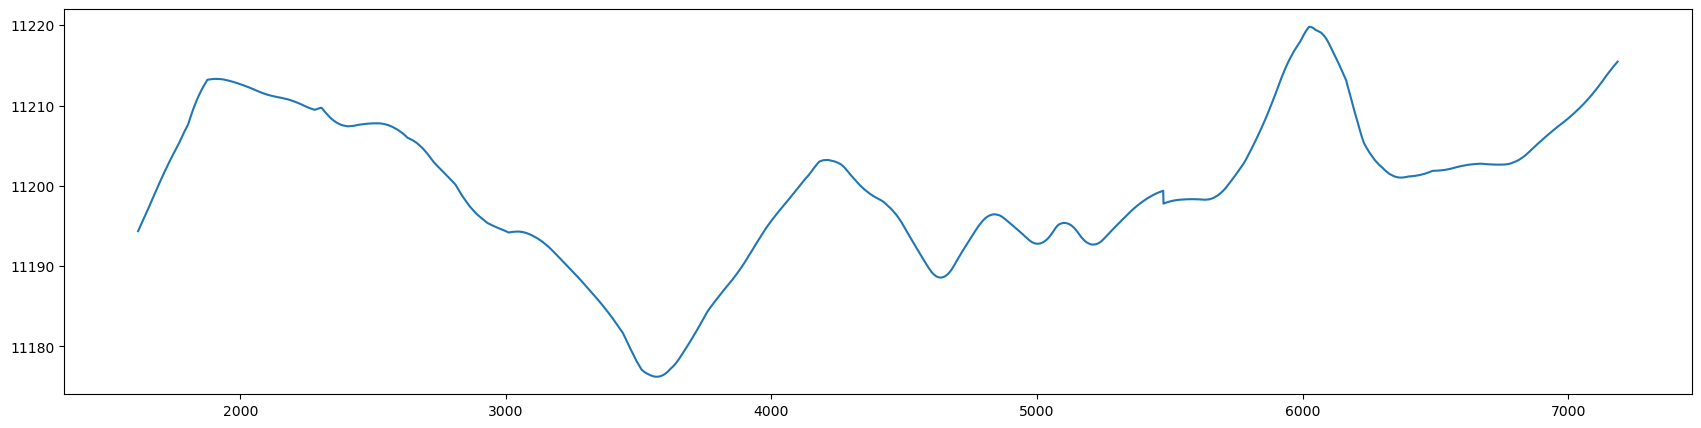

In [361]:
plt.figure(figsize=(21, 5))
plt.plot(evalz['TVT'] - evalz['norm_Z'])